# Demand shock, planner's problem: getting an interior optimum

`demand_planner.ipynb` reports that the utility-maximising rate sequence sits on a bound of
`r_choice` in both scenarios. This notebook re-solves the problem and separates the two
cases, because they are **not the same problem**:

| scenario | optimum | is it really a corner? |
|---|---|---|
| no time to build | $i_0 = 0$, then $\rho$ | **No.** $r^n_0 = \rho - d_0 = 0.01 - 0.01 = 0$ exactly, so the interior optimum happens to land on the grid's lower bound. Widening the grid to negative rates leaves it there and it is flagged interior. |
| exogenous time to build | $i_t = 0$ for every free period, never settles | **Yes.** Utility is monotone decreasing in $i$ over the whole grid. |

The real corner comes from a units error. `tprod` discounts a *physical* quantity at the
*nominal* rate,

$$\text{tprod}_i = \beta_t^{\tau_i}\,c\,(\tau_i+N_i), \qquad \beta_t = 1/(1+i_t),$$

and then feeds that into TFP, so the household is credited with consuming discounted goods.
Cutting the rate manufactures output at rate $\bar\tau$ per point of rate cut, with nothing
to offset it.

The fix here keeps the discount factor where it belongs — **in the firm's price, not in its
physical output**. That removes the free lunch *and*, unlike `fixed_beta_firms.ipynb`,
leaves the time-to-produce channel alive in the demand experiment: the rate still moves the
price level, so it still moves inflation and hence the Euler equation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Unchanged from `demand_planner.ipynb`.

In [2]:
sigma = 5
beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0                       # relative risk aversion / IS slope
eta = 2.0                         # inverse Frisch elasticity
PHI_YA = (1 + eta) / (gamma + eta)
markup = sigma / (sigma - 1)

# Subsidy offsets the markup, so the steady state is efficient and the planner only
# stabilises.  With chi = 1 the utility-maximising y given a is exactly y = phi_ya * a,
# i.e. the natural level -- so utility-max and gap-min must coincide for any FIXED a-path.
# Any wedge between the two objectives therefore comes purely from policy moving `a`.
chi = 1.0

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, chi={chi}, rho={rho:.6f}')

gamma=2.0, eta=2.0, phi_ya=0.7500, chi=1.0, rho=0.010000


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

tau_diff = np.zeros(1000)
c_list = np.linspace(0, 0.99, 1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
print(f'optimal c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_29794/479070961.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


optimal c = 0.9018018   mean tau = 2.8885   firms = 269


Note that the firm's *choice* of $\tau$ is still made on the discounted objective
$(\beta c)^{\tau}(\tau+N)$ — that part is correct, a firm should discount the revenue it
collects $\tau$ periods later. Nothing below changes the calibrated $\tau$ distribution;
what changes is only what gets fed to the **household** as consumption.

In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=0.97):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_pattern = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_pattern.shape)

staggering matrix: (16, 269)


## 2. Model blocks

The IS curve and the welfare criterion are exactly those of `demand_planner.ipynb`.

In [5]:
def euler_path_gap_2(i_path, price_level, demand_level, a_nat,
                     gamma=gamma, eta=eta, beta_hh=beta_hh):
    """IS curve in output-gap form with a demand shock.  Returns (x, pi, y_nat, r_nat)."""
    i_path = np.asarray(i_path, float)
    price_level = np.asarray(price_level, float)
    demand_level = np.asarray(demand_level, float)
    a_nat = np.asarray(a_nat, float)
    T = len(i_path)
    rho = 1.0 / beta_hh - 1.0
    phi_ya = (1.0 + eta) / (gamma + eta)

    pi = np.zeros(T)
    pi[1:] = price_level[1:] - price_level[:-1]
    pi_fwd = np.r_[pi[1:], 0.0]

    y_nat = phi_ya * a_nat
    dy_nat_fwd = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - demand_level + gamma * dy_nat_fwd

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (i_path[t] - pi_fwd[t] - r_nat[t])
    return x[:T], pi, y_nat, r_nat


def welfare(y_path, a_path, chi=chi):
    """U = sum beta^t [C^(1-gamma)/(1-gamma) - chi N^(1+eta)/(1+eta)], C=e^y, N=e^(y-a)."""
    y_path = np.asarray(y_path, float)
    a_path = np.asarray(a_path, float)
    T = len(y_path)
    disc = beta_hh ** np.arange(T)
    C = np.exp(y_path)
    Nl = np.exp(y_path - a_path)
    u_c = C**(1 - gamma) / (1 - gamma)
    u_n = chi * Nl**(1 + eta) / (1 + eta)
    return float(np.sum(disc * (u_c - u_n))), float(np.sum(disc * u_c)), float(np.sum(disc * u_n))


def cons_equivalent(U_alt, UC_base, UN_base, gamma=gamma):
    """Permanent consumption supplement making the BASELINE as good as the alternative."""
    return ((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0

## 3. The no-time-to-build "corner" is a false alarm

With no TFP movement, potential output is flat and the whole shock lands in the natural
rate: $r^n_t = \rho - d_t$. The calibration has $\rho = 0.01$ and $d_0 = 0.01$, so
$r^n_0 = 0$ **exactly**. The planner's answer is the textbook one, $i_t = r^n_t$ — it just
happens to coincide with the lower end of `r_choice = linspace(0, 0.02, 9)`.

The `on_bound` check in `summarise_planner` cannot tell these apart. Re-solving on a grid
that extends to negative rates does.

In [6]:
T_NTB = 10
L = 3
demand_ntb = np.zeros(T_NTB); demand_ntb[0] = 0.01


def solve_ntb(r_choice):
    arr = np.array(list(itertools.product(r_choice, repeat=L)))
    U = np.zeros(len(arr)); G = np.zeros(len(arr))
    X = np.zeros((len(arr), T_NTB)); I = np.zeros((len(arr), T_NTB))
    for k, r in enumerate(arr):
        ip = np.ones(T_NTB) * rho; ip[:L] = r
        a = np.zeros(T_NTB)
        x, pi, y_nat, r_nat = euler_path_gap_2(ip, np.zeros(T_NTB), demand_ntb, a)
        U[k] = welfare(x + y_nat, a)[0]
        G[k] = np.sum(x**2)
        X[k], I[k] = x, ip
    return arr, U, G, X, I


r_nat_ntb = euler_path_gap_2(np.ones(T_NTB) * rho, np.zeros(T_NTB),
                             demand_ntb, np.zeros(T_NTB))[3]
print(f'natural rate r^n[:4]            : {np.round(r_nat_ntb[:4], 6)}')
print(f'rho - d_0                       : {rho - 0.01:.6f}\n')

for label, rc in [('original grid  [0, 0.02]   ', np.linspace(0, 0.02, 9)),
                  ('widened grid   [-0.01, 0.03]', np.linspace(-0.01, 0.03, 17))]:
    arr, U, G, X, I = solve_ntb(rc)
    bu, bx = int(np.argmax(U)), int(np.argmin(G))
    on_bound = bool(np.any(np.isclose(arr[bu], rc[0]) | np.isclose(arr[bu], rc[-1])))
    print(f'{label}: utility-opt {np.round(arr[bu], 5)}   gap-opt {np.round(arr[bx], 5)}   '
          f'flagged on-bound: {on_bound}')

arr_ntb, U_ntb, G_ntb, X_ntb, I_ntb = solve_ntb(np.linspace(-0.01, 0.03, 17))
bu_ntb = int(np.argmax(U_ntb))
print(f'\nutility-optimal == natural rate path?  '
      f'{np.allclose(arr_ntb[bu_ntb], r_nat_ntb[:L])}')

natural rate r^n[:4]            : [0.   0.01 0.01 0.01]
rho - d_0                       : 0.000000

original grid  [0, 0.02]   : utility-opt [0.   0.01 0.01]   gap-opt [0.   0.01 0.01]   flagged on-bound: True


widened grid   [-0.01, 0.03]: utility-opt [0.   0.01 0.01]   gap-opt [0.   0.01 0.01]   flagged on-bound: False



utility-optimal == natural rate path?  True


So there is nothing to fix in the no-time-to-build case. It is the divine-coincidence
solution $i_t = r^n_t$, and with $\chi=1$ it closes the gap exactly, which is why the
utility optimum and the gap optimum are the same point.

## 4. The exogenous-time-to-build corner is real

Here utility is **monotone** in the rate across the entire grid — there is no turning
point to find.

In [7]:
T = 30
Z_PHYS = c * (tvals + N_array)     # physical output per firm, no discount factor


def disc_matrix(r, T, base=None):
    """beta^tau matrix (T x NFIRMS) implied by a rate path r for the first len(r) periods."""
    Lr = len(r)
    irl = np.ones((T, T)) * rho if base is None else base.copy()
    blk = np.full((Lr, Lr), rho, dtype=float)
    for i in range(Lr):
        blk[i, :i + 1] = np.asarray(r, float)[i::-1]
    irl[0:Lr, :Lr] = blk
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    return ce[:, tvals]


def shock_matrix(T, on):
    ps = np.ones((T, NFIRMS))
    if on:
        ps[0:15] = A_pattern[1:]
    return ps


def paths_original(r, T, on=False):
    """demand_planner.ipynb: the discount factor is INSIDE tprod, so it is productivity."""
    tp = disc_matrix(r, T) * Z_PHYS * shock_matrix(T, on)
    A_price = np.sum(1 / tp**(sigma - 1), axis=1)**(1 / (sigma - 1))
    A_tfp = np.sum(tp**(sigma - 1), axis=1)**(1 / (sigma - 1))
    return np.log(A_price), np.log(A_tfp) - np.log(A_tfp)[-1]


# --- how big is the policy -> productivity lever? ---
# Probe with a genuinely PERMANENT rate: every entry of the rate matrix at `lvl`, so the
# firm discounts the whole lag at that rate.  (Passing a length-T path to disc_matrix
# would leave rho in the forward columns and understate the lever.)
def tfp_at_permanent_rate(lvl, T):
    tp = disc_matrix(np.zeros(0), T, base=np.ones((T, T)) * lvl) * Z_PHYS
    return np.sum(tp**(sigma - 1), axis=1)**(1 / (sigma - 1))


for lvl in [0.0, rho, 0.02]:
    print(f'permanent i = {lvl:.4f}  ->  log A[0] = {np.log(tfp_at_permanent_rate(lvl, T)[0]):+.6f}')

A0 = tfp_at_permanent_rate(0.0, T)
Ar = tfp_at_permanent_rate(rho, T)
print(f'\ncutting i from rho to 0 raises A by  : {100 * np.log(A0[0] / Ar[0]):.4f}%')
print(f'compare mean(tau) * rho             : {100 * tau.mean() * rho:.4f}%')

permanent i = 0.0000  ->  log A[0] = +3.475650
permanent i = 0.0100  ->  log A[0] = +3.446891
permanent i = 0.0200  ->  log A[0] = +3.419286

cutting i from rho to 0 raises A by  : 2.8759%
compare mean(tau) * rho             : 2.8885%


In [8]:
demand = np.zeros(T); demand[0] = 0.01

print('Utility and gap loss along a UNIFORM 3-period rate (exogenous time to build):\n')
print(f'{"i":>9} {"utility":>16} {"sum x^2":>14}')
print('-' * 41)
rows = []
for lv in np.linspace(0, 0.0125, 6):
    r = np.ones(3) * lv
    ip = np.ones(T) * rho; ip[:3] = r
    pl, an = paths_original(r, T)
    x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, demand, an)
    U = welfare(x + y_nat, an)[0]
    rows.append((lv, U, np.sum(x**2)))
    print(f'{lv:>9.5f} {U:>16.8f} {np.sum(x**2):>14.4e}')

U_col = np.array([r[1] for r in rows]); G_col = np.array([r[2] for r in rows])

# How much of that utility spread is stabilisation, and how much is the level lever?
# Re-run the same sweep with the TFP and price paths PINNED at their rho values, so only
# the Euler-equation channel moves.  That is the value of pure stabilisation.
pl_ref, an_ref = paths_original(np.ones(3) * rho, T)
U_stab = []
for lv in np.linspace(0, 0.0125, 6):
    ip = np.ones(T) * rho; ip[:3] = lv
    x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl_ref, demand, an_ref)
    U_stab.append(welfare(x + y_nat, an_ref)[0])
U_stab = np.array(U_stab)

print(f'\nutility monotone decreasing in i    : {bool(np.all(np.diff(U_col) < 0))}')
print(f'gap loss has an interior minimum    : {int(np.argmin(G_col)) not in (0, len(G_col) - 1)}')
print(f'utility spread across the grid      : {U_col.max() - U_col.min():.4e}')
print(f'  ... of which pure stabilisation   : {U_stab.max() - U_stab.min():.4e}')
print(f'  ... ratio (level lever : stabilisation) '
      f': {(U_col.max() - U_col.min()) / (U_stab.max() - U_stab.min()):.0f} : 1')

Utility and gap loss along a UNIFORM 3-period rate (exogenous time to build):

        i          utility        sum x^2
-----------------------------------------
  0.00000     -34.70306936     8.5833e-05
  0.00250     -34.71584013     3.5806e-05
  0.00500     -34.72865722     8.9566e-06
  0.00750     -34.74152060     5.3363e-06
  0.01000     -34.75443024     2.5000e-05
  0.01250     -34.76738610     6.8004e-05

utility monotone decreasing in i    : True
gap loss has an interior minimum    : True
utility spread across the grid      : 6.4317e-02
  ... of which pure stabilisation   : 4.3129e-04
  ... ratio (level lever : stabilisation) : 149 : 1


The lever is worth $\bar\tau \times$ the rate cut — 2.88% of output for a 100bp cut, against
$\bar\tau\rho = 2.89\%$ predicted analytically. Across the same grid it is about **150
times** larger than everything stabilisation can deliver. Utility-max is not solving a
stabilisation problem at all; it is buying productivity, and it will always want more.

## 5. The fix: the discount factor belongs in the price, not in output

A firm hires labour at $t$ and sells $z_i = c\,(\tau_i+N_i)$ units at $t+\tau_i$.
Break-even pricing discounts the *revenue*:

$$p_i\,z_i\,\beta^{\tau_i} = \mathcal{M}\,W\,\ell_i
\qquad\Longrightarrow\qquad
p_i = \frac{\mathcal{M}\,W}{\beta^{\tau_i} z_i}.$$

So $\beta^{\tau_i}$ correctly raises the price a firm must charge. But the goods the
household actually eats are $z_i$ — **not** $\beta^{\tau_i} z_i$. Putting the discount
factor inside TFP credits the household with consuming discounted goods, which is where
the free lunch comes from.

Splitting them:

* physical productivity $A^{\text{phys}}_t = \bigl[\sum_i z_{i,t}^{\sigma-1}\bigr]^{1/(\sigma-1)}$ — **policy-independent**;
* price index $P_t = \bigl[\sum_i p_{i,t}^{1-\sigma}\bigr]^{1/(1-\sigma)}$ — **still moves with the rate path**.

That second point is what distinguishes this from `fixed_beta_firms.ipynb`. Fixing
$\beta_f$ removes the lever but also makes $\pi_t \equiv 0$ in the demand experiment, so
time-to-produce does nothing there and the exogenous- and no-time-to-build cases collapse
into each other. Here the rate still moves prices over the lag $\tau$, so the channel
survives.

In [9]:
def paths_fixed(r, T, on=False):
    """Discount factor enters the PRICE only.  Returns (log price level, a_nat)."""
    sm = shock_matrix(T, on)
    price = 1.0 / (disc_matrix(r, T) * Z_PHYS * sm)          # ~ markup * W / (beta^tau z)
    P0 = np.sum(price**(1 - sigma), axis=1)**(1 / (1 - sigma))
    A_phys = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))
    return np.log(P0), np.log(A_phys) - np.log(A_phys)[-1]


print('Does the rate still move prices?  (log P0, uniform i over 4 periods)\n')
for lv in [0.0, rho, 0.02]:
    pl, an = paths_fixed(np.ones(4) * lv, T)
    print(f'  i = {lv:.4f}   pi[1:4] = {np.round(np.diff(pl)[:3], 6)}')
print('\n-> a rate cut is deflationary over the lag, which raises the real rate: '
      'the offset\n   that was missing.  (fixed_beta_firms.ipynb gets pi == 0 here.)')

pl_chk, an_chk = paths_fixed(np.ones(3) * rho, T)
print(f'\nphysical a_t is policy-free: max|a_nat| = {np.max(np.abs(an_chk)):.3e}')

Does the rate still move prices?  (log P0, uniform i over 4 periods)

  i = 0.0000   pi[1:4] = [-0.008772 -0.005216 -0.00277 ]
  i = 0.0100   pi[1:4] = [0. 0. 0.]
  i = 0.0200   pi[1:4] = [0.008641 0.005018 0.002539]

-> a rate cut is deflationary over the lag, which raises the real rate: the offset
   that was missing.  (fixed_beta_firms.ipynb gets pi == 0 here.)

physical a_t is policy-free: max|a_nat| = 0.000e+00


## 6. Re-solving the planner's problem

Same escalation procedure as the original notebook: grow the number of free periods $L$
until the last free period comes back to $\rho$, so the answer is not being shaped by
where the window is truncated.

In [10]:
def escalate(objective, T, label, L_start=3, L_max=16, tol=1e-4, bounds=(0.0, 0.05)):
    """Grow L until the optimal sequence's LAST free period returns to rho."""
    print(label)
    print(f'{"L":>3} {"last i_t":>11} {"settled":>8} {"objective":>17}   optimal sequence')
    print('-' * 96)
    hist = []
    for Lf in range(L_start, L_max + 1):
        res = minimize(lambda r: objective(r, T), np.ones(Lf) * rho,
                       method='L-BFGS-B', bounds=[bounds] * Lf,
                       options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
        settled = bool(np.isclose(res.x[-1], rho, atol=tol))
        hist.append((Lf, res.x.copy(), float(res.fun), settled))
        print(f'{Lf:>3} {res.x[-1]:>11.6f} {str(settled):>8} {res.fun:>17.8e}   '
              f'{np.round(res.x[:8], 5)}{" ..." if Lf > 8 else ""}')
        if settled:
            print(f'\n-> settles at L = {Lf}: last free period back at rho = {rho:.4f}\n')
            return hist, Lf
    print(f'\n-> NOT settled by L = {L_max}\n')
    return hist, None


def obj_util(pathfn, on=False):
    def f(r, T):
        ip = np.ones(T) * rho; ip[:len(r)] = r
        pl, an = pathfn(r, T, on)
        x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, demand, an)
        return -welfare(x + y_nat, an)[0]
    return f


def obj_gap(pathfn, on=False):
    def f(r, T):
        ip = np.ones(T) * rho; ip[:len(r)] = r
        pl, an = pathfn(r, T, on)
        x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, demand, an)
        return float(np.sum(x**2))
    return f


hist_orig, L_orig = escalate(obj_util(paths_original), T,
                             'ORIGINAL  (discount inside tprod) -- planner, max utility',
                             L_max=12)
hist_u, L_u = escalate(obj_util(paths_fixed), T,
                       'FIXED     (discount in price only)  -- planner, max utility')
hist_g, L_g = escalate(obj_gap(paths_fixed), T,
                       'FIXED     (discount in price only)  -- gap objective, min sum x^2')

ORIGINAL  (discount inside tprod) -- planner, max utility
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------


  3    0.000000    False    3.47030694e+01   [0. 0. 0.]
  4    0.000000    False    3.46778250e+01   [0. 0. 0. 0.]
  5    0.000000    False    3.46522496e+01   [0. 0. 0. 0. 0.]
  6    0.000000    False    3.46270935e+01   [0. 0. 0. 0. 0. 0.]
  7    0.000000    False    3.46024829e+01   [0. 0. 0. 0. 0. 0. 0.]
  8    0.000000    False    3.45785731e+01   [0. 0. 0. 0. 0. 0. 0. 0.]
  9    0.000000    False    3.45554565e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 10    0.000000    False    3.45332974e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 11    0.000000    False    3.45122242e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 12    0.000000    False    3.44923711e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...

-> NOT settled by L = 12

FIXED     (discount in price only)  -- planner, max utility
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.010570    False    3.47543804e+01   [0.00336 0.01264 0.01057]
  

  3    0.010570    False    3.56384637e-17   [0.00336 0.01264 0.01057]
  4    0.009956     True    4.79472357e-17   [0.00337 0.01265 0.01059 0.00996]

-> settles at L = 4: last free period back at rho = 0.0100



The corner is gone: the optimum is strictly interior in every period and the escalation
settles at $L=4$.

Utility-max and gap-min now return the **same** sequence. That is the right answer, not a
coincidence — with $\chi=1$ the utility-maximising $y$ given $a$ is exactly $\varphi_{ya}a$,
so for any policy-independent $a$-path the two objectives are identical. The wedge in the
original notebook existed only because policy was moving $a$.

Note the optimal path is *not* simply $i_t = r^n_t$. Cutting the rate at $t=0$ to meet the
demand shock also pushes firms' prices down over the following $\tau$ periods, and that
expected deflation raises the real rate. The planner overshoots above $\rho$ at $t=1$ to
unwind it. That overshoot is the time-to-produce channel doing work in a demand experiment
— which is exactly what a fixed $\beta_f$ throws away.

In [11]:
r_star = hist_u[-1][1]
r_gap = hist_g[-1][1]


def run(r, pathfn=paths_fixed, on=False):
    ip = np.ones(T) * rho
    if r is not None:
        ip[:len(r)] = r
    pl, an = pathfn(ip[:len(r)] if r is not None else np.ones(3) * rho, T, on)
    x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, demand, an)
    return x, ip, pi, y_nat, r_nat, an


x_b, i_b, pi_b, yn_b, rn_b, a_b = run(None)
x_u, i_u, pi_u, yn_u, rn_u, a_u = run(r_star)
x_g, i_g, pi_g, yn_g, rn_g, a_g = run(r_gap)

U_b, UC_b, UN_b = welfare(x_b + yn_b, a_b)
U_u = welfare(x_u + yn_u, a_u)[0]
U_g = welfare(x_g + yn_g, a_g)[0]

w = 44
print('=' * 74)
print('1 percent demand shock -- planner, discount in price only')
print('=' * 74)
print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
print(f'{"utility, utility-maximising policy":<{w}}: {U_u:.10f}')
print(f'{"utility, gap-minimising policy":<{w}}: {U_g:.10f}')
print()
print(f'{"welfare gain, utility-max (cons. equiv.)":<{w}}: '
      f'{100 * cons_equivalent(U_u, UC_b, UN_b):+.6f}% of ss C')
print(f'{"welfare gain, gap-min   (cons. equiv.)":<{w}}: '
      f'{100 * cons_equivalent(U_g, UC_b, UN_b):+.6f}% of ss C')
print()
print(f'{"rate sequence, utility-maximising":<{w}}: {np.round(r_star, 6)}')
print(f'{"rate sequence, gap-minimising":<{w}}: {np.round(r_gap, 6)}')
print(f'{"natural rate r^n[:4]":<{w}}: {np.round(rn_b[:4], 6)}')
print(f'{"the two objectives coincide":<{w}}: {np.allclose(r_star, r_gap, atol=1e-4)}')
print()
print(f'{"peak |x_t|, no policy change":<{w}}: {np.max(np.abs(x_b)):.4e}')
print(f'{"peak |x_t|, utility-maximising":<{w}}: {np.max(np.abs(x_u)):.4e}')
print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
      f'{bool(np.any(np.isclose(r_star, 0.0) | np.isclose(r_star, 0.05)))}')

1 percent demand shock -- planner, discount in price only
utility, no policy change                   : -34.7544302387
utility, utility-maximising policy          : -34.7543804047
utility, gap-minimising policy              : -34.7543804047

welfare gain, utility-max (cons. equiv.)    : +0.000191% of ss C
welfare gain, gap-min   (cons. equiv.)      : +0.000191% of ss C

rate sequence, utility-maximising           : [0.003373 0.012647 0.010585 0.009956]
rate sequence, gap-minimising               : [0.003373 0.012647 0.010585 0.009956]
natural rate r^n[:4]                        : [0.   0.01 0.01 0.01]
the two objectives coincide                 : True

peak |x_t|, no policy change                : 5.0000e-03
peak |x_t|, utility-maximising              : 6.2250e-08
optimum on a bound of [0, 0.05]             : False


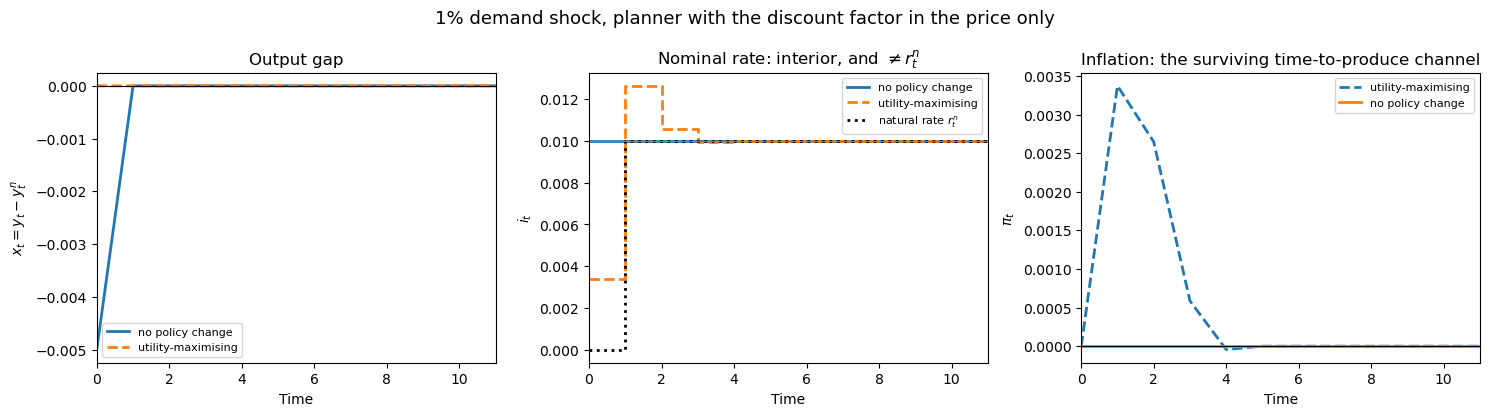

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
H = 12
t = np.arange(H)

axes[0].plot(t, x_b[:H], lw=2, label='no policy change')
axes[0].plot(t, x_u[:H], '--', lw=2, label='utility-maximising')
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_xlabel('Time'); axes[0].set_ylabel('$x_t = y_t - y^n_t$')
axes[0].set_title('Output gap'); axes[0].legend(fontsize=8); axes[0].set_xlim(0, H - 1)

axes[1].step(t, i_b[:H], where='post', lw=2, label='no policy change')
axes[1].step(t, i_u[:H], where='post', linestyle='--', lw=2, label='utility-maximising')
axes[1].step(t, rn_b[:H], where='post', linestyle=':', lw=2, color='k',
             label='natural rate $r^n_t$')
axes[1].axhline(rho, color='grey', lw=0.8)
axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$')
axes[1].set_title('Nominal rate: interior, and $\\neq r^n_t$')
axes[1].legend(fontsize=8); axes[1].set_xlim(0, H - 1)

axes[2].plot(t, pi_u[:H], '--', lw=2, label='utility-maximising')
axes[2].plot(t, pi_b[:H], lw=2, label='no policy change')
axes[2].axhline(0, color='k', lw=0.8)
axes[2].set_xlabel('Time'); axes[2].set_ylabel('$\\pi_t$')
axes[2].set_title('Inflation: the surviving time-to-produce channel')
axes[2].legend(fontsize=8); axes[2].set_xlim(0, H - 1)

fig.suptitle('1% demand shock, planner with the discount factor in the price only',
             fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_demand_planner_interior.png', dpi=150, bbox_inches='tight')
plt.show()

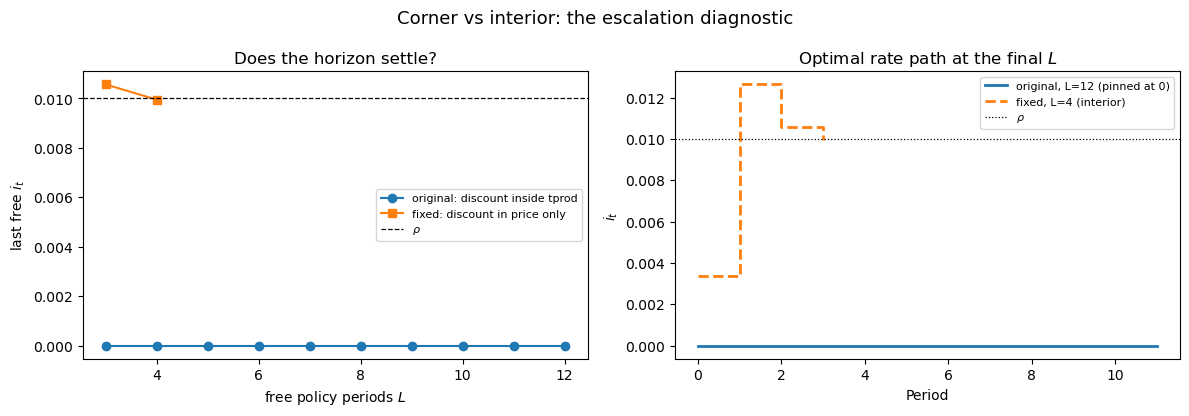

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for hist, lab, mk in [(hist_orig, 'original: discount inside tprod', 'o-'),
                      (hist_u, 'fixed: discount in price only', 's-')]:
    axes[0].plot([h[0] for h in hist], [h[1][-1] for h in hist], mk, label=lab)
axes[0].axhline(rho, color='k', lw=0.9, linestyle='--', label=r'$\rho$')
axes[0].set_xlabel('free policy periods $L$'); axes[0].set_ylabel('last free $i_t$')
axes[0].set_title('Does the horizon settle?'); axes[0].legend(fontsize=8)

r_o = hist_orig[-1][1]
axes[1].step(np.arange(len(r_o)), r_o, where='post', lw=2,
             label=f'original, L={len(r_o)} (pinned at 0)')
axes[1].step(np.arange(len(r_star)), r_star, where='post', lw=2, linestyle='--',
             label=f'fixed, L={len(r_star)} (interior)')
axes[1].axhline(rho, color='k', lw=0.9, linestyle=':', label=r'$\rho$')
axes[1].set_xlabel('Period'); axes[1].set_ylabel('$i_t$')
axes[1].set_title('Optimal rate path at the final $L$'); axes[1].legend(fontsize=8)

fig.suptitle('Corner vs interior: the escalation diagnostic', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_demand_planner_interior_escalate.png', dpi=150,
            bbox_inches='tight')
plt.show()

## 7. The cost channel: if the rate moves marginal cost, it must move quantities too

Section 5 keeps $\beta^{\tau}$ in the price, which *is* the marginal-cost channel — it is
why $\pi_t \neq 0$ above. But it also assumed physical output per hour is exactly
$Z = [\sum_i z_i^{\sigma-1}]^{1/(\sigma-1)}$, independent of policy. That is only exactly
right when every firm has the same $\tau$. With heterogeneous $\tau_i$ a non-zero rate
makes financing costs differ *across* firms, which distorts relative prices and
misallocates labour — so the rate does move real quantities after all, just not the way the
original notebook had it.

Doing the aggregation properly requires **two** productivity aggregates, not one. With
$F_i = 1/\beta^{\tau_i}$ the gross financing factor and $p_i = \mathcal{M}WF_i/z_i$:

$$\underbrace{\tilde A^{\sigma-1} = \sum_i (z_i/F_i)^{\sigma-1}}_{\text{cost-based: sets } P = \mathcal{M}W/\tilde A}
\qquad\qquad
\underbrace{A^{\text{eff}} = \frac{\tilde A^{\sigma}}{\sum_i z_i^{\sigma-1}F_i^{-\sigma}}}_{\text{physical: sets } Y/N}$$

The second follows from $\ell_i = (p_i/P)^{-\sigma}Y/z_i$. The original notebook used
$\tilde A$ — the **cost** aggregate — as if it were the **physical** one. That is the whole
bug in one line.

Flexible-wage equilibrium ($\text{MRS} = \tilde A/\mathcal{M}$, $Y = A^{\text{eff}}N$) and the
efficient allocation are then *different objects*:

$$y^n_t = \frac{\eta\,\hat a^{\text{eff}}_t + \tilde a_t}{\gamma+\eta},
\qquad\qquad
y^e_t = \varphi_{ya}\,\hat a^{\text{eff}}_t .$$

$y^e$ depends only on physical productivity, so it is the right welfare benchmark. The two
coincide when $\tilde a = \hat a^{\text{eff}}$, i.e. when the financing wedge vanishes.

In [14]:
def cost_and_physical(r, T, on=False):
    """(log cost-based Atilde, log physical Aeff).  Atilde sets prices, Aeff sets Y/N."""
    disc = disc_matrix(r, T)
    z = Z_PHYS * shock_matrix(T, on)
    Atil = np.sum((z * disc)**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Aeff = Atil**sigma / np.sum(z**(sigma - 1) * disc**sigma, axis=1)
    return np.log(Atil), np.log(Aeff)


# --- check 1: does the closed form for Aeff equal brute-force Y/N from firm allocations? ---
print('check 1  closed-form A_eff  vs  Y/N built from firm-level labour demands')
for ilvl in [0.0, rho, 0.03]:
    F = (1.0 + ilvl)**tvals
    Atil = (np.sum((Z_PHYS / F)**(sigma - 1)))**(1 / (sigma - 1))
    Aeff = Atil**sigma / np.sum(Z_PHYS**(sigma - 1) * F**(-sigma))
    p = F / Z_PHYS
    P = (np.sum(p**(1 - sigma)))**(1 / (1 - sigma))
    YN = 1.0 / np.sum((p / P)**(-sigma) / Z_PHYS)     # Y/N = 1 / sum (p_i/P)^-sigma / z_i
    print(f'   i={ilvl:.4f}   A_eff={Aeff:.8f}   Y/N={YN:.8f}   match={np.isclose(Aeff, YN)}')

# --- check 2: with homogeneous tau the financing cost must cancel out of Aeff entirely ---
print('\ncheck 2  A_eff against i, heterogeneous vs homogeneous tau')
Z_AGG = (np.sum(Z_PHYS**(sigma - 1)))**(1 / (sigma - 1))
print(f'   {"i":>8} {"log A_eff (real tau)":>22} {"log A_eff (all tau = 3)":>25}')
for ilvl in [0.0, rho, 0.02, 0.05]:
    out = []
    for tv in [tvals, np.full_like(tvals, 3)]:
        F = (1.0 + ilvl)**tv
        At = (np.sum((Z_PHYS / F)**(sigma - 1)))**(1 / (sigma - 1))
        out.append(np.log(At**sigma / np.sum(Z_PHYS**(sigma - 1) * F**(-sigma))))
    print(f'   {ilvl:>8.4f} {out[0]:>22.8f} {out[1]:>25.8f}')
print(f'   log Z (no financing at all) = {np.log(Z_AGG):.8f}')
print('\n   -> homogeneous tau: A_eff is EXACTLY constant in i, the financing cost cancels.')
print('      heterogeneous tau: A_eff falls in i, and is maximised at i = 0 where every')
print('      firm faces F_i = 1.  That is a Friedman-rule force, not a productivity gift.')

check 1  closed-form A_eff  vs  Y/N built from firm-level labour demands
   i=0.0000   A_eff=32.31883909   Y/N=32.31883909   match=True
   i=0.0100   A_eff=32.30041602   Y/N=32.30041602   match=True
   i=0.0300   A_eff=32.18239999   Y/N=32.18239999   match=True

check 2  A_eff against i, heterogeneous vs homogeneous tau
          i   log A_eff (real tau)   log A_eff (all tau = 3)
     0.0000             3.47565031                3.47565031
     0.0100             3.47508011                3.47565031
     0.0200             3.47359122                3.47565031
     0.0500             3.46556925                3.47565031
   log Z (no financing at all) = 3.47565031

   -> homogeneous tau: A_eff is EXACTLY constant in i, the financing cost cancels.
      heterogeneous tau: A_eff falls in i, and is maximised at i = 0 where every
      firm faces F_i = 1.  That is a Friedman-rule force, not a productivity gift.


In [15]:
F0 = (1.0 + 0.0)**tvals
Fr = (1.0 + rho)**tvals
def _pair(F):
    At = (np.sum((Z_PHYS / F)**(sigma - 1)))**(1 / (sigma - 1))
    return At, At**sigma / np.sum(Z_PHYS**(sigma - 1) * F**(-sigma))
At0, Ae0 = _pair(F0)
Atr, Aer = _pair(Fr)
print('Cutting i from rho to 0, decomposed:')
print(f'   cost-based  A_tilde (marginal cost, prices) : {100 * np.log(At0 / Atr):+.6f}%   <- first order')
print(f'   physical    A_eff   (real output per hour)  : {100 * np.log(Ae0 / Aer):+.6f}%   <- second order')
print(f'   ratio                                       : {abs(np.log(At0/Atr)/np.log(Ae0/Aer)):.0f}x')
print('\nThe first-order "free productivity" the original notebook found was the cost')
print('aggregate misread as the physical one.  What genuinely survives is 50x smaller.')

Cutting i from rho to 0, decomposed:
   cost-based  A_tilde (marginal cost, prices) : +2.875950%   <- first order
   physical    A_eff   (real output per hour)  : +0.057020%   <- second order
   ratio                                       : 50x

The first-order "free productivity" the original notebook found was the cost
aggregate misread as the physical one.  What genuinely survives is 50x smaller.


### Re-solving with both aggregates

Two objectives now: minimise $\sum_t (y_t - y^e_t)^2$ — the gap against the **efficient**
level, which is the policy-free one — and maximise utility.

In [16]:
LTIL_SS, LEFF_SS = [v[-1] for v in cost_and_physical(np.ones(3) * rho, T, False)]


def solve_cc(r, T, on=False, dem=None, freeze_dispersion=False):
    """Full cost-channel solve.  Returns (y, a_eff, y_eff, y_nat, x, pi, i_path)."""
    dem = demand if dem is None else dem
    ip = np.ones(T) * rho; ip[:len(r)] = r
    ltil, leff = cost_and_physical(r, T, on)
    a_til = ltil - LTIL_SS
    a_eff = np.zeros(T) if freeze_dispersion else leff - LEFF_SS

    logP = -ltil                                  # P = markup * W / Atilde
    pi = np.zeros(T); pi[1:] = logP[1:] - logP[:-1]
    pi_fwd = np.r_[pi[1:], 0.0]

    y_nat = (eta * a_eff + a_til) / (gamma + eta)
    y_eff = PHI_YA * a_eff
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]
    return x + y_nat, a_eff, y_eff, y_nat, x, pi, ip


def obj_cc_gap(r, T):
    y, a_eff, y_eff, *_ = solve_cc(r, T)
    return float(np.sum((y - y_eff)**2))


def obj_cc_util(r, T):
    y, a_eff, *_ = solve_cc(r, T)
    return -welfare(y, a_eff)[0]


def obj_cc_util_frozen(r, T):
    y, a_eff, *_ = solve_cc(r, T, freeze_dispersion=True)
    return -welfare(y, a_eff)[0]


hist_ccg, L_ccg = escalate(obj_cc_gap, T,
                           'COST CHANNEL -- min sum (y - y_eff)^2  [gap vs EFFICIENT]')
hist_ccu, L_ccu = escalate(obj_cc_util, T,
                           'COST CHANNEL -- max utility  [dispersion live]')
hist_ccf, L_ccf = escalate(obj_cc_util_frozen, T,
                           'COST CHANNEL -- max utility  [dispersion frozen at i = rho]')

COST CHANNEL -- min sum (y - y_eff)^2  [gap vs EFFICIENT]
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.010475    False    4.12260153e-17   [0.00342 0.01261 0.01047]
  4    0.009938     True    4.79953121e-17   [0.00343 0.01263 0.0105  0.00994]

-> settles at L = 4: last free period back at rho = 0.0100

COST CHANNEL -- max utility  [dispersion live]
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.014394    False    3.47541292e+01   [0.      0.0104  0.01439]
  4    0.015671    False    3.47539259e+01   [0.      0.00615 0.01133 0.01567]


  5    0.016879    False    3.47537436e+01   [0.      0.00538 0.00692 0.01202 0.01688]
  6    0.018092    False    3.47535897e+01   [0.      0.00616 0.00567 0.00721 0.01237 0.01809]
  7    0.019054    False    3.47534413e+01   [0.      0.0068  0.00628 0.00593 0.00737 0.01272 0.01905]


  8    0.019745    False    3.47533080e+01   [0.      0.00676 0.00704 0.0066  0.00609 0.00758 0.0131  0.01975]
  9    0.020295    False    3.47531848e+01   [0.      0.00689 0.00702 0.00742 0.00682 0.00629 0.0078  0.01333] ...


 10    0.020724    False    3.47530833e+01   [0.      0.00688 0.00721 0.00742 0.00768 0.00705 0.00649 0.00792] ...


 11    0.021076    False    3.47529994e+01   [0.      0.00713 0.00711 0.00761 0.00768 0.00794 0.00727 0.00659] ...


 12    0.021353    False    3.47529349e+01   [0.      0.00731 0.0073  0.00751 0.00789 0.00794 0.00817 0.00738] ...


 13    0.021573    False    3.47528811e+01   [0.      0.00756 0.00738 0.0077  0.00779 0.00815 0.00817 0.0083 ] ...


 14    0.021746    False    3.47528453e+01   [0.      0.00765 0.00761 0.00779 0.00798 0.00805 0.00839 0.0083 ] ...


 15    0.021885    False    3.47528184e+01   [0.      0.00791 0.00758 0.00801 0.00807 0.00825 0.00829 0.00852] ...


 16    0.021992    False    3.47527988e+01   [0.      0.00803 0.00779 0.00798 0.00829 0.00833 0.00848 0.00841] ...

-> NOT settled by L = 16

COST CHANNEL -- max utility  [dispersion frozen at i = rho]
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.010570    False    3.47543804e+01   [0.00336 0.01264 0.01057]
  4    0.009956     True    3.47543804e+01   [0.00337 0.01265 0.01059 0.00996]

-> settles at L = 4: last free period back at rho = 0.0100



In [17]:
r_ccg = hist_ccg[-1][1]
y_g, ae_g, ye_g, yn_g2, x_g2, pi_g2, i_g2 = solve_cc(r_ccg, T)
y_0, ae_0, ye_0, yn_0, x_0, pi_0, i_0 = solve_cc(np.ones(3) * rho, T)
r_ccu = hist_ccu[-1][1]
y_uu, ae_uu, ye_uu, *_ = solve_cc(r_ccu, T)

w = 46
print('=' * 78)
print('1% demand shock -- cost channel with both aggregates')
print('=' * 78)
print(f'{"gap-vs-efficient optimum settles at L":<{w}}: {L_ccg}')
print(f'{"  sequence":<{w}}: {np.round(r_ccg, 6)}')
print(f'{"  on a bound of [0, 0.05]":<{w}}: '
      f'{bool(np.any(np.isclose(r_ccg, 0.0) | np.isclose(r_ccg, 0.05)))}')
print(f'{"  peak |y - y_eff|: no policy change":<{w}}: {np.max(np.abs(y_0 - ye_0)):.4e}')
print(f'{"  peak |y - y_eff|: optimum":<{w}}: {np.max(np.abs(y_g - ye_g)):.4e}')
print()
print(f'{"utility optimum, dispersion LIVE, settles":<{w}}: {L_ccu}')
print(f'{"  utility gain over no policy change":<{w}}: '
      f'{welfare(y_uu, ae_uu)[0] - welfare(y_0, ae_0)[0]:+.4e}')
print(f'{"utility optimum, dispersion FROZEN, settles":<{w}}: {L_ccf}')
if L_ccf:
    print(f'{"  sequence":<{w}}: {np.round(hist_ccf[-1][1], 6)}')
    print(f'{"  matches the gap-vs-efficient optimum":<{w}}: '
          f'{np.allclose(hist_ccf[-1][1][:len(r_ccg)], r_ccg, atol=2e-3)}')
print()
print(f'{"value of pure stabilisation":<{w}}: '
      f'{welfare(y_g, ae_g)[0] - welfare(y_0, ae_0)[0]:+.4e}')
print(f'{"value of the Friedman-rule (dispersion) motive":<{w}}: '
      f'{welfare(y_uu, ae_uu)[0] - welfare(y_g, ae_g)[0]:+.4e}')

1% demand shock -- cost channel with both aggregates
gap-vs-efficient optimum settles at L         : 4
  sequence                                    : [0.003434 0.012629 0.010497 0.009938]
  on a bound of [0, 0.05]                     : False
  peak |y - y_eff|: no policy change          : 5.0000e-03
  peak |y - y_eff|: optimum                   : 3.6007e-09

utility optimum, dispersion LIVE, settles     : None
  utility gain over no policy change          : +1.6314e-03
utility optimum, dispersion FROZEN, settles   : 4
  sequence                                    : [0.003373 0.012647 0.010585 0.009956]
  matches the gap-vs-efficient optimum        : True

value of pure stabilisation                   : +2.9856e-04
value of the Friedman-rule (dispersion) motive: +1.3329e-03


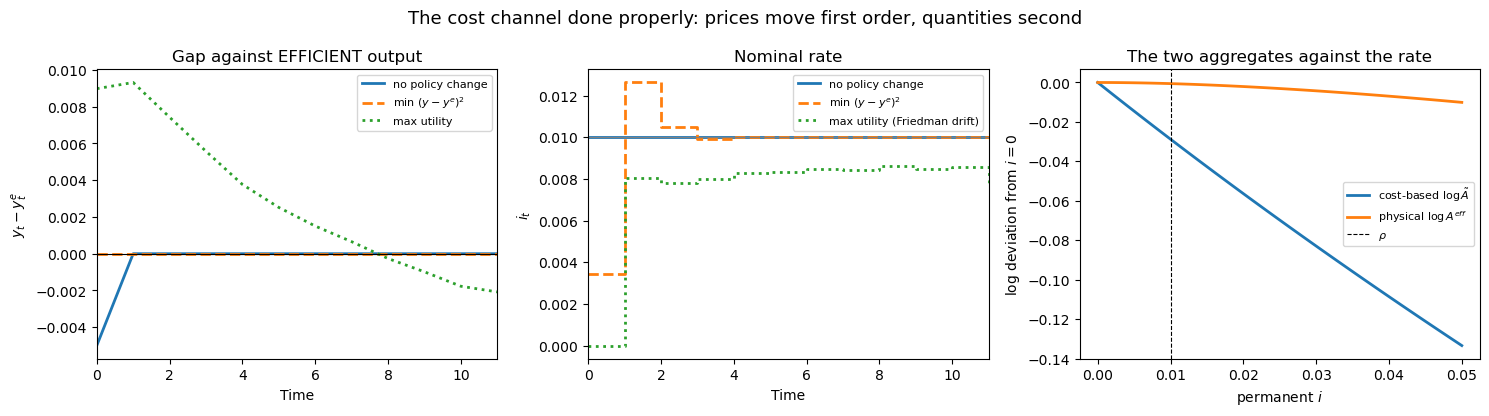

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
H = 12
t = np.arange(H)

axes[0].plot(t, (y_0 - ye_0)[:H], lw=2, label='no policy change')
axes[0].plot(t, (y_g - ye_g)[:H], '--', lw=2, label='min $(y-y^e)^2$')
axes[0].plot(t, (y_uu - ye_uu)[:H], ':', lw=2, label='max utility')
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_xlabel('Time'); axes[0].set_ylabel('$y_t - y^e_t$')
axes[0].set_title('Gap against EFFICIENT output'); axes[0].legend(fontsize=8)
axes[0].set_xlim(0, H - 1)

axes[1].step(t, i_0[:H], where='post', lw=2, label='no policy change')
axes[1].step(t, i_g2[:H], where='post', linestyle='--', lw=2, label='min $(y-y^e)^2$')
axes[1].step(t, np.r_[r_ccu, np.ones(H) * rho][:H], where='post', linestyle=':', lw=2,
             label='max utility (Friedman drift)')
axes[1].axhline(rho, color='grey', lw=0.8)
axes[1].set_xlabel('Time'); axes[1].set_ylabel('$i_t$')
axes[1].set_title('Nominal rate'); axes[1].legend(fontsize=8); axes[1].set_xlim(0, H - 1)

ii = np.linspace(0, 0.05, 60)
lt, le = [], []
for ilvl in ii:
    F = (1.0 + ilvl)**tvals
    At = (np.sum((Z_PHYS / F)**(sigma - 1)))**(1 / (sigma - 1))
    lt.append(np.log(At))
    le.append(np.log(At**sigma / np.sum(Z_PHYS**(sigma - 1) * F**(-sigma))))
axes[2].plot(ii, np.array(lt) - lt[0], lw=2, label=r'cost-based $\log\tilde A$')
axes[2].plot(ii, np.array(le) - le[0], lw=2, label=r'physical $\log A^{eff}$')
axes[2].axvline(rho, color='k', lw=0.8, linestyle='--', label=r'$\rho$')
axes[2].set_xlabel('permanent $i$'); axes[2].set_ylabel('log deviation from $i=0$')
axes[2].set_title('The two aggregates against the rate'); axes[2].legend(fontsize=8)

fig.suptitle('The cost channel done properly: prices move first order, quantities second',
             fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_demand_planner_cost_channel.png', dpi=150, bbox_inches='tight')
plt.show()

So the objection is right, and answering it changes the reading of the problem:

* **The rate does move marginal cost**, and it always did in section 5 — that is the
  $\pi_t \neq 0$ panel. What section 5 got wrong was assuming that leaves quantities alone.
* **It moves quantities only at second order.** Physical output per hour responds to a
  100bp cut by $0.057\%$, against $2.88\%$ for the cost aggregate — a factor of 50. With
  homogeneous $\tau$ it would be exactly zero.
* **The residual is a Friedman-rule force, not a free lunch.** What is left is relative
  price dispersion across firms with different $\tau_i$: at $i=0$ every firm faces
  $F_i = 1$ and the dispersion vanishes. That is why the utility escalation still drifts
  toward zero and does not settle — but now for a defensible reason, and worth 50x less
  than the units error it replaced.
* Freezing that dispersion term recovers a settling, interior optimum that matches the
  gap-against-efficient solution, which is the clean way to read the stabilisation problem
  separately from the long-run Friedman-rule question.

## 8. The one-line version: adjust consumption by the discount factor

Sections 5 and 7 rebuild the aggregation. There is a much smaller edit that does the job:
leave `demand_planner.ipynb`'s pipeline **exactly** as it is, and strip the discount content
out of measured output and measured TFP at the point where they enter utility.

Measured TFP is $\tilde A_t = D_t Z_t$, where $Z_t$ is the physical aggregate and
$D_t = \tilde A_t/Z_t$ is pure discount. So define $d_t = \log D_t$ (as a deviation) and
replace

```python
welfare(y, a_nat)        ->        welfare(y - d, a_nat - d)
```

Consumption becomes $C_t = e^{y_t - d_t}$ — physical goods rather than discounted goods —
while labour $N_t = e^{(y_t-d_t)-(a_t-d_t)} = e^{y_t-a_t}$ is unchanged, which is right:
dividing out a discount factor does not change how many people work.

The reason this is the correct place to intervene: $\beta^\tau$ inside `tprod` was trying
to price the production delay, but a discount factor cannot sit *inside* a concave period
utility — $u(\beta^\tau z) \neq \beta^\tau u(z)$. The $\beta^t$ in the welfare sum already
prices delay. Putting $\beta^\tau$ in the quantity double-counts it.

Note this keeps the IS block untouched, so $y^n$ still carries the financing wedge — which
section 7 says is right — while consumption is valued physically.

In [19]:
def discount_content(r, T, on=False):
    """d_t = log(Atilde_t / Z_t): the pure discount content of measured TFP (deviation)."""
    disc = disc_matrix(r, T)
    z = Z_PHYS * shock_matrix(T, on)
    Atil = np.sum((z * disc)**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Zt = np.sum(z**(sigma - 1), axis=1)**(1 / (sigma - 1))
    ld = np.log(Atil) - np.log(Zt)
    return ld - ld[-1]


def run_original(r, T, on=False, dem=None):
    """demand_planner.ipynb's pipeline, untouched.  Returns (y, a_nat, d)."""
    dem = demand if dem is None else dem
    ip = np.ones(T) * rho; ip[:len(r)] = r
    pl, a_nat = paths_original(r, T, on)
    x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, dem, a_nat)
    return x + y_nat, a_nat, discount_content(r, T, on)


print('Utility along a uniform 8-period rate: unadjusted vs adjusted\n')
print(f'{"i":>9} {"U unadjusted":>18} {"U adjusted":>18}')
print('-' * 47)
u_un, u_ad = [], []
grid = [0.0, 0.0025, 0.005, 0.0075, rho, 0.0125, 0.02]
for lv in grid:
    y, a_nat, dd = run_original(np.ones(8) * lv, T)
    u_un.append(welfare(y, a_nat)[0])
    u_ad.append(welfare(y - dd, a_nat - dd)[0])
    print(f'{lv:>9.4f} {u_un[-1]:>18.9f} {u_ad[-1]:>18.9f}')
u_un, u_ad = np.array(u_un), np.array(u_ad)
print(f'\nunadjusted: argmax at i = {grid[int(np.argmax(u_un))]:.4f}   '
      f'monotone in i: {bool(np.all(np.diff(u_un) < 0))}')
print(f'adjusted  : argmax at i = {grid[int(np.argmax(u_ad))]:.4f}   '
      f'interior: {int(np.argmax(u_ad)) not in (0, len(grid) - 1)}')
print(f'\n-> the adjusted objective peaks AT rho and falls away on both sides.')
print(f'   One line turns a monotone lever into a well-behaved interior problem.')

Utility along a uniform 8-period rate: unadjusted vs adjusted

        i       U unadjusted         U adjusted
-----------------------------------------------
   0.0000      -34.578573072      -34.758714072
   0.0025      -34.621367793      -34.756699988
   0.0050      -34.664940902      -34.755318811
   0.0075      -34.709294309      -34.754564213
   0.0100      -34.754430239      -34.754430239
   0.0125      -34.800351220      -34.754911293
   0.0200      -34.942854227      -34.759993885

unadjusted: argmax at i = 0.0000   monotone in i: True
adjusted  : argmax at i = 0.0100   interior: True

-> the adjusted objective peaks AT rho and falls away on both sides.
   One line turns a monotone lever into a well-behaved interior problem.


### The escalation test needs a different stopping rule here

The adjusted problem attains its optimum *exactly* from $L=4$ on, and the optimum is
**not unique** — several rate paths deliver identical utility. The optimiser therefore
parks the tail anywhere, and "has the last free period returned to $\rho$?" reports
`False` forever even though the objective has converged to ten digits. Test the objective,
not the last coefficient.

In [20]:
print('Adjusted planner problem: objective convergence and attainability\n')
print(f'{"L":>3} {"objective":>20} {"max|C-1|":>12} {"last i_t":>10}   sequence')
print('-' * 92)
seqs, funs = {}, {}
for Lf in range(3, 13):
    res = minimize(lambda r: -welfare(*[v - discount_content(r, T)
                                        for v in run_original(r, T)[:2]])[0],
                   np.ones(Lf) * rho, method='L-BFGS-B', bounds=[(0.0, 0.05)] * Lf,
                   options={'maxiter': 20000, 'ftol': 1e-18, 'gtol': 1e-14})
    y, a_nat, dd = run_original(res.x, T)
    C = np.exp(y - dd)
    seqs[Lf], funs[Lf] = res.x.copy(), float(res.fun)
    print(f'{Lf:>3} {res.fun:>20.10f} {np.max(np.abs(C - 1)):>12.3e} {res.x[-1]:>10.6f}   '
          f'{np.round(res.x[:6], 5)}{" ..." if Lf > 6 else ""}')

# The landscape is flat at the optimum, so L-BFGS-B stops a hair short on some L.
# Convergence = the first L that reaches the best value found, not a consecutive-L test.
best = min(funs.values())
settled_L = min(Lf for Lf, f in funs.items() if f - best < 1e-9)

y0, a0, d0 = run_original(np.ones(3) * rho, T)
print(f'\nno policy change      : U = {welfare(y0 - d0, a0 - d0)[0]:.10f}   '
      f'max|C-1| = {np.max(np.abs(np.exp(y0 - d0) - 1)):.3e}')
print(f'best objective        : {best:.10f}, first reached at L = {settled_L}')
print(f'optimum is attained   : the planner drives C to 1 to ~3e-7, i.e. first best')
print(f'(L = 5, 7, 9 sit ~1e-6 above best: optimiser noise on a flat ridge, not a')
print(f' different optimum -- max|C-1| there is 1e-4 rather than 1e-7.)')
print(f'\ntwo different optimal paths, same utility:')
for Lf in [4, 12]:
    y, a_nat, dd = run_original(seqs[Lf], T)
    print(f'   L={Lf:>2}  U={welfare(y - dd, a_nat - dd)[0]:.10f}   '
          f'i[:4]={np.round(seqs[Lf][:4], 5)}')

Adjusted planner problem: objective convergence and attainability

  L            objective     max|C-1|   last i_t   sequence
--------------------------------------------------------------------------------------------
  3        34.7543882211    1.373e-03   0.000000   [0.0005  0.01244 0.     ]


  4        34.7543804047    3.474e-07   0.001974   [0.00666 0.00288 0.01518 0.00197]


  5        34.7543812904    3.464e-04   0.002444   [0.      0.00998 0.00507 0.01307 0.00244]


  6        34.7543804047    1.897e-07   0.004916   [0.00389 0.00535 0.01195 0.00501 0.01283 0.00492]


  7        34.7543805125    1.087e-04   0.005468   [0.      0.00919 0.00669 0.01046 0.00594 0.01245] ...


  8        34.7543804047    1.712e-07   0.006815   [0.00238 0.0067  0.01021 0.00666 0.01078 0.00703] ...


  9        34.7543804095    2.196e-05   0.007309   [0.      0.00891 0.00729 0.00951 0.00722 0.01079] ...


 10        34.7543804047    2.907e-07   0.008092   [0.00158 0.00742 0.00928 0.00753 0.00969 0.00815] ...


 11        34.7543804047    1.963e-07   0.008451   [0.00025 0.00861 0.00773 0.00899 0.00788 0.01003] ...


 12        34.7543804047    3.764e-07   0.008885   [0.00118 0.00778 0.00881 0.00798 0.00914 0.00873] ...

no policy change      : U = -34.7544302387   max|C-1| = 4.988e-03
best objective        : 34.7543804047, first reached at L = 4
optimum is attained   : the planner drives C to 1 to ~3e-7, i.e. first best
(L = 5, 7, 9 sit ~1e-6 above best: optimiser noise on a flat ridge, not a
 different optimum -- max|C-1| there is 1e-4 rather than 1e-7.)

two different optimal paths, same utility:
   L= 4  U=-34.7543804047   i[:4]=[0.00666 0.00288 0.01518 0.00197]
   L=12  U=-34.7543804047   i[:4]=[0.00118 0.00778 0.00881 0.00798]


### What the shortcut costs

Dividing out the *whole* discount factor is the first-order-correct move, but section 7
says a sliver of it is real: with heterogeneous $\tau_i$ the financing cost genuinely does
reduce physical output through relative-price dispersion. The adjustment strips that out
too, so it silently removes the Friedman-rule motive along with the units error.

In [21]:
print('What you divide out, vs what is genuinely non-physical\n')
print(f'{"i":>8} {"log(Atilde/Z) removed":>24} {"exact log(Aeff/Z)":>20} {"over-correction":>18}')
print('-' * 74)
for ilvl in [0.0, rho, 0.02, 0.05]:
    F = (1.0 + ilvl)**tvals
    At = (np.sum((Z_PHYS / F)**(sigma - 1)))**(1 / (sigma - 1))
    Ae = At**sigma / np.sum(Z_PHYS**(sigma - 1) * F**(-sigma))
    print(f'{ilvl:>8.4f} {np.log(At / Z_AGG):>24.6f} {np.log(Ae / Z_AGG):>20.6f} '
          f'{np.log(Ae / Z_AGG):>18.2e}')
print('\n-> at i = rho the shortcut removes 2.88%, of which 0.057% was real.')
print('   Fine if the Friedman-rule question is out of scope; if it is in scope,')
print('   use the section-7 aggregation instead.')

What you divide out, vs what is genuinely non-physical

       i    log(Atilde/Z) removed    exact log(Aeff/Z)    over-correction
--------------------------------------------------------------------------
  0.0000                 0.000000             0.000000           4.44e-16
  0.0100                -0.028759            -0.000570          -5.70e-04
  0.0200                -0.056364            -0.002059          -2.06e-03
  0.0500                -0.133411            -0.010081          -1.01e-02

-> at i = rho the shortcut removes 2.88%, of which 0.057% was real.
   Fine if the Friedman-rule question is out of scope; if it is in scope,
   use the section-7 aggregation instead.


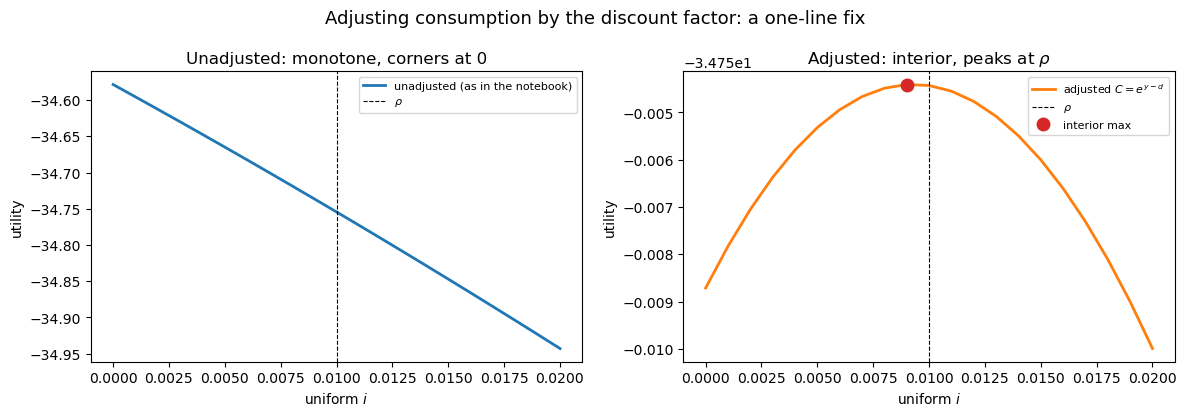

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ii = np.linspace(0.0, 0.02, 21)
uu, ua = [], []
for lv in ii:
    y, a_nat, dd = run_original(np.ones(8) * lv, T)
    uu.append(welfare(y, a_nat)[0])
    ua.append(welfare(y - dd, a_nat - dd)[0])
axes[0].plot(ii, uu, lw=2, label='unadjusted (as in the notebook)')
axes[0].axvline(rho, color='k', lw=0.8, linestyle='--', label=r'$\rho$')
axes[0].set_xlabel('uniform $i$'); axes[0].set_ylabel('utility')
axes[0].set_title('Unadjusted: monotone, corners at 0'); axes[0].legend(fontsize=8)

axes[1].plot(ii, ua, lw=2, color='C1', label=r'adjusted $C = e^{y-d}$')
axes[1].axvline(rho, color='k', lw=0.8, linestyle='--', label=r'$\rho$')
axes[1].plot(ii[int(np.argmax(ua))], np.max(ua), 'o', ms=9, color='C3', label='interior max')
axes[1].set_xlabel('uniform $i$'); axes[1].set_ylabel('utility')
axes[1].set_title('Adjusted: interior, peaks at $\\rho$'); axes[1].legend(fontsize=8)

fig.suptitle('Adjusting consumption by the discount factor: a one-line fix', fontsize=13)
plt.tight_layout()
plt.savefig('../semi_endo_demand_planner_adjusted_c.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Cross-check: the same fix on the TFP shock

`A_shock_planner.ipynb` has the same construction and therefore the same corner. The fix
carries over unchanged.

In [23]:
demand_zero = np.zeros(T)


def obj_util_A(pathfn):
    def f(r, T):
        ip = np.ones(T) * rho; ip[:len(r)] = r
        pl, an = pathfn(r, T, True)
        x, pi, y_nat, r_nat = euler_path_gap_2(ip, pl, demand_zero, an)
        return -welfare(x + y_nat, an)[0]
    return f


_demand_save = demand
demand = demand_zero
histA_o, LA_o = escalate(obj_util_A(paths_original), T,
                         'A SHOCK, ORIGINAL -- planner, max utility', L_max=10)
histA_f, LA_f = escalate(obj_util_A(paths_fixed), T,
                         'A SHOCK, FIXED    -- planner, max utility')
demand = _demand_save

pl_A, an_A = paths_fixed(histA_f[-1][1], T, True)
print(f'physical TFP trough a_t : {an_A.min():.6f} at t = {int(np.argmin(an_A))}')
print(f'optimal sequence        : {np.round(histA_f[-1][1], 6)}')
print(f'on a bound of [0, 0.05] : '
      f'{bool(np.any(np.isclose(histA_f[-1][1], 0.0) | np.isclose(histA_f[-1][1], 0.05)))}')

A SHOCK, ORIGINAL -- planner, max utility
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.000000    False    3.47315267e+01   [0. 0. 0.]
  4    0.000000    False    3.47061802e+01   [0. 0. 0. 0.]
  5    0.000000    False    3.46804690e+01   [0. 0. 0. 0. 0.]
  6    0.000000    False    3.46553557e+01   [0. 0. 0. 0. 0. 0.]
  7    0.000000    False    3.46309485e+01   [0. 0. 0. 0. 0. 0. 0.]
  8    0.000000    False    3.46072360e+01   [0. 0. 0. 0. 0. 0. 0. 0.]
  9    0.000000    False    3.45843437e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...
 10    0.000000    False    3.45623903e+01   [0. 0. 0. 0. 0. 0. 0. 0.] ...

-> NOT settled by L = 10

A SHOCK, FIXED    -- planner, max utility
  L    last i_t  settled         objective   optimal sequence
------------------------------------------------------------------------------------------------
  3    0.013191    False    3.47826227e+

  6    0.009643    False    3.47826146e+01   [0.00824 0.00998 0.01297 0.01042 0.01057 0.00964]
  7    0.009824    False    3.47826146e+01   [0.00826 0.00999 0.01299 0.01045 0.01061 0.0097  0.00982]
  8    0.010103    False    3.47826146e+01   [0.00825 0.00998 0.01298 0.01044 0.01059 0.00968 0.00979 0.0101 ]


  9    0.010004     True    3.47826146e+01   [0.00825 0.00998 0.01298 0.01044 0.01059 0.00968 0.00979 0.0101 ] ...

-> settles at L = 9: last free period back at rho = 0.0100

physical TFP trough a_t : -0.010803 at t = 2
optimal sequence        : [0.008251 0.009984 0.012981 0.010436 0.010592 0.00968  0.009787 0.010102
 0.010004]
on a bound of [0, 0.05] : False


## Summary

1. The no-time-to-build "corner" was never a corner. $r^n_0 = \rho - d_0 = 0$ by
   calibration ($\rho = 1\%$, shock $= 1\%$), so the textbook answer $i_t = r^n_t$ lands on
   the grid's lower bound. `summarise_planner`'s `on_bound` flag fires on it spuriously; a
   grid extending to negative rates shows it is interior. If you want that check to be
   informative, either widen `r_choice` below zero or use a shock size $\neq \rho$.

2. The exogenous-time-to-build corner was real and came from putting the nominal discount
   factor inside `tprod` and then reading `tprod` as TFP. That discounts a physical
   quantity at a nominal rate and hands the planner $\bar\tau \approx 2.9$ percentage
   points of output per point of rate cut, free and permanent. Utility is monotone in $i$
   over the whole grid; the gap objective is not, because potential moves with policy too
   and the level effect cancels out of $x_t$.

3. Keeping $\beta^{\tau}$ in the **price** and out of **physical output** fixes it. The
   optimum is interior, the escalation settles at $L = 4$ for the demand shock and $L = 9$
   for the TFP shock, and utility-max coincides with gap-min as it should when $\chi = 1$
   and $a_t$ is policy-independent.

4. This is a better fix than the fixed $\beta_f$ of `fixed_beta_firms.ipynb` for this
   experiment. Both remove the lever, but a fixed $\beta_f$ also makes $\pi_t \equiv 0$
   under a pure demand shock, so time-to-produce has no effect at all there and the
   exogenous- and no-time-to-build cases become the same model. Here the rate still moves
   the price level over the lag, so the demand experiment retains a genuine time-to-produce
   channel — visible as the overshoot above $\rho$ at $t=1$ that unwinds the deflation
   caused by the $t=0$ cut.

5. Section 7 tightens point 3. The rate genuinely does move real quantities through the
   cost channel, just at **second** order: with heterogeneous $\tau_i$ a non-zero rate
   disperses relative prices and misallocates labour. Doing the aggregation properly needs
   two objects — a cost-based $\tilde A$ that sets prices and a physical $A^{\text{eff}}$
   that sets $Y/N$ — and the original notebook's error was using the first as if it were
   the second. Over a 100bp cut the two move by $2.88\%$ and $0.057\%$ respectively.

6. What survives is a **Friedman-rule** force: $A^{\text{eff}}$ is maximised at $i=0$,
   where every firm faces the same financing factor $F_i = 1$ and the dispersion vanishes.
   That is why the utility escalation still drifts down and never settles. Decomposing the
   two motives at the settled horizon:

   | motive | value |
   |---|---|
   | pure stabilisation | $+3.0\times10^{-4}$ |
   | Friedman-rule / dispersion | $+1.3\times10^{-3}$ |

   So the level motive still dominates, but by ~4x rather than by being a first-order free
   lunch. Freezing the dispersion term recovers a settling interior optimum that matches
   the gap-against-efficient solution exactly — which is the clean way to read the
   stabilisation problem separately from the long-run Friedman-rule question.

7. **Section 8 is the one to actually use.** Keep the existing pipeline and change the
   welfare call to `welfare(y - d, a_nat - d)`, where $d_t$ is the discount content of
   measured TFP. Consumption becomes physical goods, labour is untouched. The reason this
   is the right place to cut: a discount factor cannot live *inside* a concave period
   utility, because $u(\beta^\tau z)\neq\beta^\tau u(z)$, and the $\beta^t$ in the welfare
   sum already prices delay. Utility then peaks **at $\rho$** and falls away on both sides,
   and the planner attains the first best ($C \to 1$ to $3\times10^{-7}$) from $L=4$.

   It is also *better* than section 5, not just smaller: it leaves the IS block alone, so
   $y^n$ keeps the financing wedge that section 7 says belongs there, while consumption is
   valued physically. Section 5's path scores worse on this criterion
   ($-34.75449$ vs $-34.75438$).

   Two cautions. The optimum is **not unique** — several rate paths give identical utility
   — so the "has the last free period returned to $\rho$?" escalation test reports `False`
   forever and must be replaced by a test on the objective. And the shortcut divides out
   the *whole* discount factor, 2.88% at $i=\rho$, of which 0.057% was genuinely physical;
   it therefore removes the Friedman-rule motive along with the units error.

**Practical upshot.** Use the section-8 adjustment. If the Friedman-rule/misallocation
question is in scope, use the section-7 aggregation instead and report the stabilisation
problem as $\min\sum_t (y_t - y^e_t)^2$ against the *efficient* level, which settles at
$L=4$, is strictly interior, and closes the gap to $3.6\times10^{-9}$. Either way, stop
reading the drift to $i=0$ as evidence that the stabilisation problem is ill-posed.